# Assignment 2

In this assigment, we will work with the *Forest Fire* data set. Please download the data from the [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/162/forest+fires). Extract the data files into the subdirectory: `../data/fires/` (relative to `./05_src/`).

## Objective

+ The model objective is to predict the area affected by forest fires given the features set. 
+ The objective of this exercise is to assess your ability to construct and evaluate model pipelines.
+ Please note: the instructions are not meant to be 100% prescriptive, but instead they are a set of minimum requirements. If you find predictive performance gains by applying additional steps, by all means show them. 

## Variable Description

From the description file contained in the archive (`forestfires.names`), we obtain the following variable descriptions:

1. X - x-axis spatial coordinate within the Montesinho park map: 1 to 9
2. Y - y-axis spatial coordinate within the Montesinho park map: 2 to 9
3. month - month of the year: "jan" to "dec" 
4. day - day of the week: "mon" to "sun"
5. FFMC - FFMC index from the FWI system: 18.7 to 96.20
6. DMC - DMC index from the FWI system: 1.1 to 291.3 
7. DC - DC index from the FWI system: 7.9 to 860.6 
8. ISI - ISI index from the FWI system: 0.0 to 56.10
9. temp - temperature in Celsius degrees: 2.2 to 33.30
10. RH - relative humidity in %: 15.0 to 100
11. wind - wind speed in km/h: 0.40 to 9.40 
12. rain - outside rain in mm/m2 : 0.0 to 6.4 
13. area - the burned area of the forest (in ha): 0.00 to 1090.84 









### Specific Tasks

+ Construct four model pipelines, out of combinations of the following components:

    + Preprocessors:

        - A simple processor that only scales numeric variables and recodes categorical variables.
        - A transformation preprocessor that scales numeric variables and applies a non-linear transformation.
    
    + Regressor:

        - A baseline regressor, which could be a [K-nearest neighbours model]() or a linear model like [Lasso](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html) or [Ridge Regressors](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ridge_regression.html).
        - An advanced regressor of your choice (e.g., Bagging, Boosting, SVR, etc.). TIP: select a tree-based method such that it does not take too long to run SHAP further below. 

+ Evaluate tune and evaluate each of the four model pipelines. 

    - Select a [performance metric](https://scikit-learn.org/stable/modules/linear_model.html) out of the following options: explained variance, max error, root mean squared error (RMSE), mean absolute error (MAE), r-squared.
    - *TIPS*: 
    
        * Out of the suggested metrics above, [some are correlation metrics, but this is a prediction problem](https://www.tmwr.org/performance#performance). Choose wisely (and don't choose the incorrect options.) 

+ Select the best-performing model and explain its predictions.

    - Provide local explanations.
    - Obtain global explanations and recommend a variable selection strategy.

+ Export your model as a pickle file.


You can work on the Jupyter notebook, as this experiment is fairly short (no need to use sacred). 

# Load the data

Place the files in the ../../05_src/data/fires/ directory and load the appropriate file. 

In [1]:
from pathlib import Path
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score
from sklearn.metrics import mean_absolute_error

SEED = 42

c:\Users\mjabbar4\Documents\DSI\production\production-env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
data_path = Path("../../05_src/data/fires/forestfires.csv")

In [3]:
columns = ['coord_x', 'coord_y', 'month', 'day', 'ffmc', 'dmc', 'dc', 'isi', 'temp', 'rh', 'wind', 'rain', 'area']
fires_dt = (pd.read_csv('../../05_src/data/fires/forestfires.csv', header = 0, names = columns))
fires_dt.info()


<class 'pandas.DataFrame'>
RangeIndex: 517 entries, 0 to 516
Data columns (total 13 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   coord_x  517 non-null    int64  
 1   coord_y  517 non-null    int64  
 2   month    517 non-null    str    
 3   day      517 non-null    str    
 4   ffmc     517 non-null    float64
 5   dmc      517 non-null    float64
 6   dc       517 non-null    float64
 7   isi      517 non-null    float64
 8   temp     517 non-null    float64
 9   rh       517 non-null    int64  
 10  wind     517 non-null    float64
 11  rain     517 non-null    float64
 12  area     517 non-null    float64
dtypes: float64(8), int64(3), str(2)
memory usage: 55.7 KB


# Get X and Y

Create the features data frame and target data.

In [4]:
X = fires_dt.drop(columns="area")     # X alwasy feature/predictor variables
print("Features:", X.shape)


Features: (517, 12)


In [5]:
y = fires_dt["area"]       # Y always target/study/dependent variable
print("Target:", y.shape)

Target: (517,)


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)
print('Training set:', X_train.shape)
print('Test set:', X_test.shape)

Training set: (413, 12)
Test set: (104, 12)


In [7]:
display(y_train.describe())

count    413.000000
mean      11.132131
std       45.658548
min        0.000000
25%        0.000000
50%        0.540000
75%        6.570000
max      746.280000
Name: area, dtype: float64

In [9]:
print(f'Zero values in training: {y_train.eq(0).mean():.1%}')

Zero values in training: 47.5%


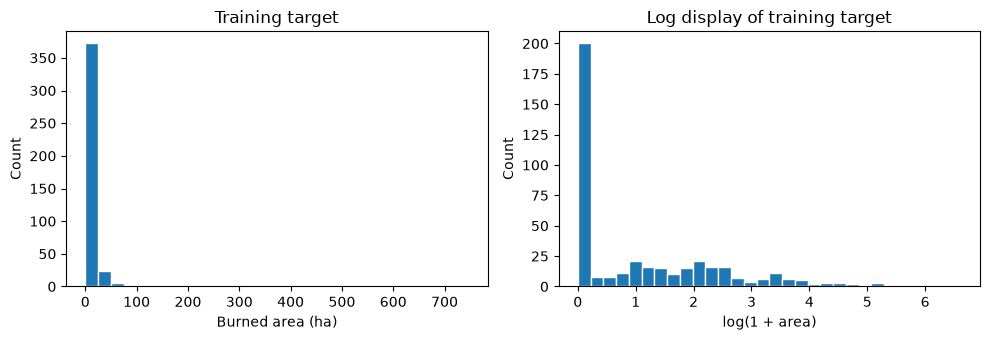

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(y_train, bins=30, edgecolor='white')
axes[0].set(xlabel='Burned area (ha)', ylabel='Count', title='Training target')
axes[1].hist(np.log1p(y_train), bins=30, edgecolor='white')
axes[1].set(xlabel='log(1 + area)', ylabel='Count', title='Log display of training target')
plt.tight_layout()
plt.show()

Too many zeros (almost 50%), and few large burned areas. Use MAE because it measures the average absolute error, as it less affected by very large errors than RMSE.
Log histogram is just to display before and after log(1+area) transformation. test 20% and 5-fold CV on the training.

# Preprocessing

Create two [Column Transformers](https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html), called preproc1 and preproc2, with the following guidelines:

- Numerical variables

    * (Preproc 1 and 2) Scaling: use a scaling method of your choice (Standard, Robust, Min-Max). 
    * Preproc 2 only: 
        
        + Choose a transformation for any of your input variables (or several of them). Evaluate if this transformation is convenient.
        + The choice of scaler is up to you.

- Categorical variables: 
    
    * (Preproc 1 and 2) Apply [one-hot encoding](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html) where appropriate.


+ The only difference between preproc1 and preproc2 is the non-linear transformation of the numerical variables.
    


### Preproc 1

Create preproc1 below.

+ Numeric: scaled variables, no other transforms.
+ Categorical: one-hot encoding.

In [12]:
numeric_features = ['dmc', 'dc', 'isi', 'rain', 'coord_x', 'coord_y', 'ffmc', 'temp', 'rh', 'wind']
categorical = ['month', 'day']

preproc1 = ColumnTransformer([
    ('numeric_features', StandardScaler(), numeric_features),
    ('categorical', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical) ])

### Preproc 2

Create preproc1 below.

+ Numeric: scaled variables, non-linear transformation to one or more variables.
+ Categorical: one-hot encoding.

In [13]:
log_scaler = Pipeline([
    ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
    ('scale', StandardScaler()) ])
preproc2 = ColumnTransformer([
    ('numeric_features', log_scaler, numeric_features),
    ('categorical', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical) ])

Preproc1 standardizes all numeric X variables. 
Preproc2 log1p to the same numeric X variables & then standardizes. 
Both use the one-hot encoding for month and day, as asked. 
All numeric were nonnegative, so log1p is defined, including for 0 rainfall. 

## Model Pipeline


Create a [model pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html): 

+ Add a step labelled `preprocessing` and assign the Column Transformer from the previous section.
+ Add a step labelled `regressor` and assign a regression model to it. 

## Regressor

+ Use a regression model to perform a prediction. 

    - Choose a baseline regressor, tune it (if necessary) using grid search, and evaluate it using cross-validation.
    - Choose a more advance regressor, tune it (if necessary) using grid search, and evaluate it using cross-validation.
    - Both model choices are up to you, feel free to experiment.

In [14]:
pipeline_A = Pipeline([
    ('preprocessing', clone(preproc1)),
    ('regressor', Ridge()) ])

In [15]:
pipeline_B = Pipeline([
    ('preprocessing', clone(preproc2)),
    ('regressor', Ridge()) ])

In [16]:
pipeline_C = Pipeline([
    ('preprocessing', clone(preproc1)),
    ('regressor', RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=1)) ])

In [17]:
pipeline_D = Pipeline([
    ('preprocessing', clone(preproc2)),
    ('regressor', RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=1))])

Ridge is baseline model while Random Forest is advanced model. 
A and B use Ridge; 
C and D use Random Forest. 
Same CV folds are used for all 4 pipelines. 
Ridge has four parameter combinations and Random Forest has eight.

# Tune Hyperparams

+ Perform GridSearch on each of the four pipelines. 
+ Tune at least one hyperparameter per pipeline.
+ Experiment with at least four value combinations per pipeline.

In [18]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
ridge_grid = {'regressor__alpha': [0.1, 1, 10, 100]}
forest_grid = {
    'regressor__max_depth': [None, 8],
    'regressor__min_samples_leaf': [1, 5],
    'regressor__max_features': [0.7, 1.0]  }
searches = {}

4 combinations for each Ridge pipeline.

In [19]:
for name, pipeline in [('A', pipeline_A), ('B', pipeline_B)]:
    searches[name] = GridSearchCV(
        pipeline, ridge_grid, scoring='neg_mean_absolute_error',
        cv=cv, n_jobs=-1, refit=True, error_score='raise'
    ).fit(X_train, y_train)
    print(name, searches[name].best_params_)

A {'regressor__alpha': 100}
B {'regressor__alpha': 100}


8 combinations each Random Forest pipeline.

In [20]:
for name, pipeline in [('C', pipeline_C), ('D', pipeline_D)]:
    searches[name] = GridSearchCV(
        pipeline, forest_grid, scoring='neg_mean_absolute_error',
        cv=cv, n_jobs=-1, refit=True, error_score='raise'
    ).fit(X_train, y_train)
    print(name, searches[name].best_params_)

C {'regressor__max_depth': None, 'regressor__max_features': 0.7, 'regressor__min_samples_leaf': 5}
D {'regressor__max_depth': None, 'regressor__max_features': 0.7, 'regressor__min_samples_leaf': 5}


In [21]:
rows = []
for name, search in searches.items():
    rows.append({
        'Pipeline': name,
        'CV MAE (ha)': -search.best_score_,
        'Fold SD': search.cv_results_['std_test_score'][search.best_index_],
        'Combinations': len(search.cv_results_['params']),
        'Best parameters': search.best_params_
    })
results = pd.DataFrame(rows).set_index('Pipeline').sort_values('CV MAE (ha)')
display(results)

,CV MAE (ha),Fold SD,Combinations,Best parameters
Pipeline,,,,
B,16.615798,1.990961,4,{'regressor__alpha': 100}
A,16.858785,1.866613,4,{'regressor__alpha': 100}
C,17.397791,2.662554,8,"{'regressor__max_depth': None, 'regressor__max..."
D,17.434222,2.655376,8,"{'regressor__max_depth': None, 'regressor__max..."


In [22]:
for model, simple, transformed in [('Ridge', 'A', 'B'), ('Random Forest', 'C', 'D')]:
    change = results.loc[transformed, 'CV MAE (ha)'] - results.loc[simple, 'CV MAE (ha)']
    print(f'{model}: log preprocessing changes CV MAE by {change:.3f} ha.')
print('Negative changes favour log preprocessing.')

Ridge: log preprocessing changes CV MAE by -0.243 ha.
Random Forest: log preprocessing changes CV MAE by 0.036 ha.
Negative changes favour log preprocessing.


# Evaluate

+ Which model has the best performance?

,Model,CV MAE (ha),Test MAE (ha)
0,Pipeline B,16.615798,24.279402
1,Training median,11.147132,19.649808


Selected pipeline: B
Negative test predictions: 4


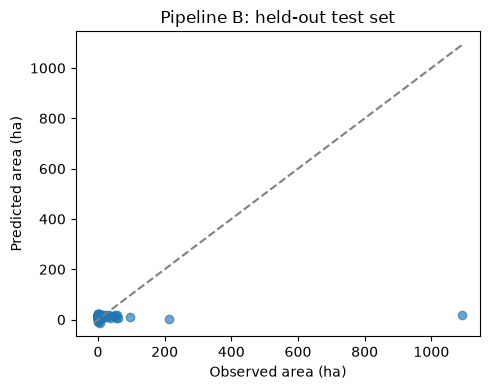

In [23]:
# Select with CV only; not from test scores
best_name = results.index[0]
best_model = searches[best_name].best_estimator_
predictions = best_model.predict(X_test)
test_mae = mean_absolute_error(y_test, predictions)

reference = DummyRegressor(strategy='median')
reference_cv = -cross_val_score(
    reference, X_train, y_train, scoring='neg_mean_absolute_error', cv=cv
).mean()
reference.fit(X_train, y_train)
reference_test = mean_absolute_error(y_test, reference.predict(X_test))
display(pd.DataFrame({
    'Model': [f'Pipeline {best_name}', 'Training median'],
    'CV MAE (ha)': [results.loc[best_name, 'CV MAE (ha)'], reference_cv],
    'Test MAE (ha)': [test_mae, reference_test]
}))
print('Selected pipeline:', best_name)
print('Negative test predictions:', int((predictions < 0).sum()))

plt.figure(figsize=(5, 4))
plt.scatter(y_test, predictions, alpha=0.65)
lo = min(0, predictions.min())
hi = max(y_test.max(), predictions.max())
plt.plot([lo, hi], [lo, hi], '--', color='grey')
plt.xlabel('Observed area (ha)')
plt.ylabel('Predicted area (ha)')
plt.title(f'Pipeline {best_name}: held-out test set')
plt.tight_layout()
plt.show()


B had lowest CV MAE among 4 pipelines. Test MAE was 24.279 ha.
Training Median reference CV MAE 11.147 and test MAE 19.650. 
Selected pipeline did not beat this simple reference on the test set. 
Being best among 4 pipelines does not necessarily mean that the model predicts well.

For Ridge, log preprocessing changed CV MAE by -0.243. 
For Random Forest the change was 0.036. 
The small difference for Random Forest is expected because log1p preserves the ordering of each predictor.

# Export

+ Save the best performing model to a pickle file.

In [24]:
model_path = Path('best_forest_fire_pipeline.pkl')
with model_path.open('wb') as file:
    pickle.dump(best_model, file)
print('Saved:', model_path.name)

Saved: best_forest_fire_pipeline.pkl


In [25]:
with model_path.open('rb') as file:
    saved_model = pickle.load(file)
np.testing.assert_allclose(saved_model.predict(X_test), predictions)
print('Reload check passed.')

Reload check passed.


# Explain

+ Use SHAP values to explain the following only for the best-performing model:

    - Select an observation in your test set and explain which are the most important features that explain that observation's specific prediction.

    - In general, across the complete training set, which features are the most and least important.

+ If you were to remove features from the model, which ones would you remove? Why? How would you test that these features are actually enhancing model performance?

,coord_x,coord_y,month,day,ffmc,dmc,dc,isi,temp,rh,wind,rain
304,6,5,may,sat,85.1,28.0,113.8,3.5,11.3,94,4.9,0.0


Observed: 0.000 ha; predicted: 7.007 ha
SHAP reference: 10.413 ha


,Feature,Contribution (ha)
0,numeric_features__dmc,-4.110992
8,numeric_features__rh,-3.685083
4,numeric_features__coord_x,1.926271
7,numeric_features__temp,-1.793686
24,categorical__day_sat,0.888383
9,numeric_features__wind,0.831981
1,numeric_features__dc,0.483774
2,numeric_features__isi,0.479410


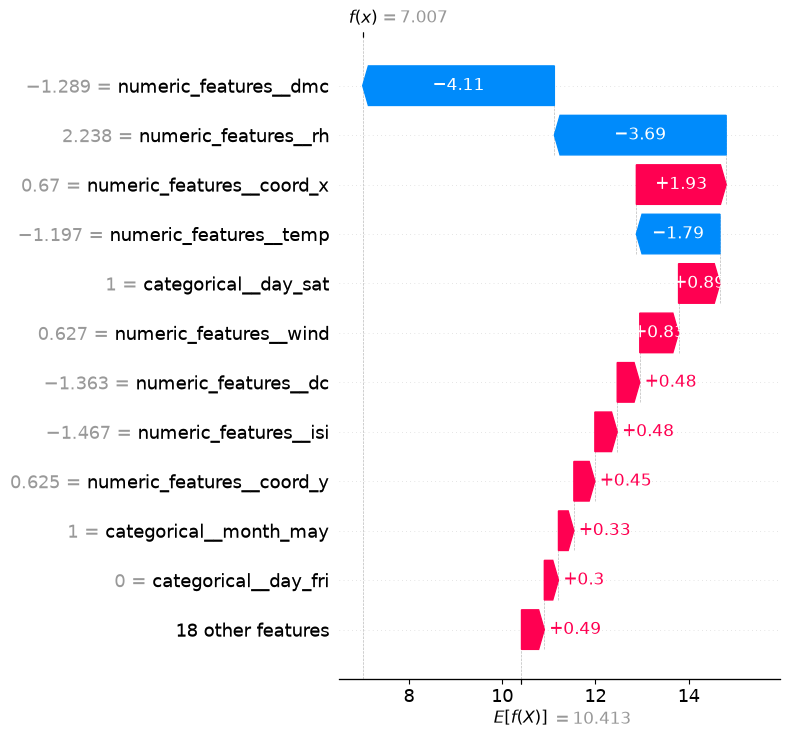

In [26]:
preprocessor = best_model.named_steps['preprocessing']
regressor = best_model.named_steps['regressor']
train_transformed = np.asarray(preprocessor.transform(X_train), dtype=float)
test_transformed = np.asarray(preprocessor.transform(X_test), dtype=float)
feature_names = preprocessor.get_feature_names_out().tolist()

rng = np.random.default_rng(SEED)
background = train_transformed[rng.choice(len(X_train), size=100, replace=False)]
if isinstance(regressor, RandomForestRegressor):
    explainer = shap.TreeExplainer(
        regressor, data=background, feature_perturbation='interventional',
        model_output='raw', feature_names=feature_names
    )
else:
    explainer = shap.LinearExplainer(
        regressor, shap.maskers.Independent(background), feature_names=feature_names
    )

# Explain the first test observation, chosen before inspecting its error.
local_shap = explainer(test_transformed[:1])
local_prediction = float(predictions[0])
local_base = float(np.asarray(local_shap.base_values).reshape(-1)[0])
local_values = local_shap.values[0]
np.testing.assert_allclose(
    local_base + local_values.sum(), local_prediction, rtol=1e-4, atol=1e-4
)
display(X_test.iloc[[0]])
print(f'Observed: {y_test.iloc[0]:.3f} ha; predicted: {local_prediction:.3f} ha')
print(f'SHAP reference: {local_base:.3f} ha')
local_table = pd.DataFrame({'Feature': feature_names, 'Contribution (ha)': local_values})
local_table = local_table.iloc[np.argsort(-np.abs(local_values))]
display(local_table.head(8))
shap.plots.waterfall(local_shap[0], max_display=12, show=False)
plt.tight_layout()
plt.show()


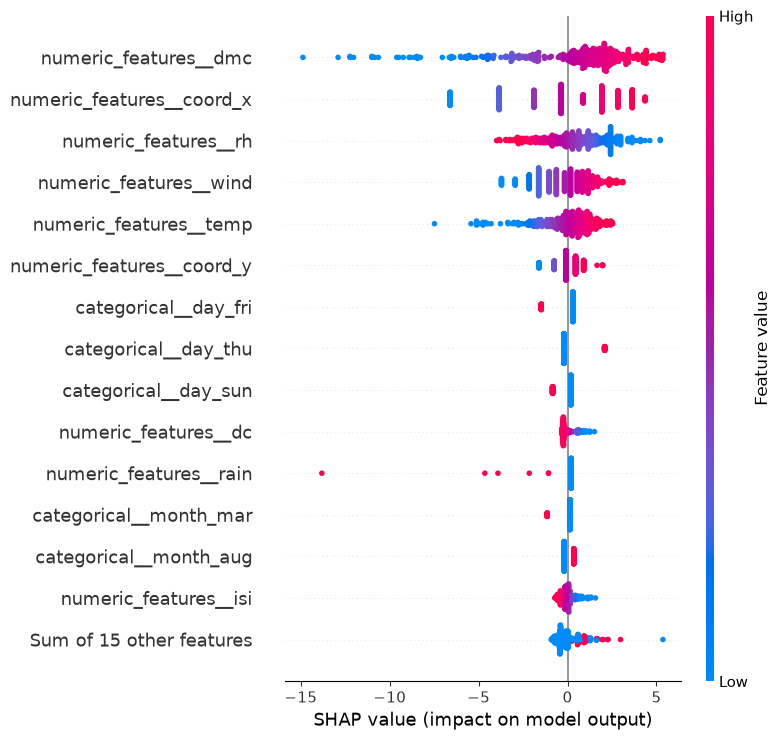

,Mean absolute grouped SHAP (ha)
dmc,2.730774
coord_x,2.612969
rh,1.459808
wind,1.208998
temp,1.081449
day,0.936119
month,0.569826
coord_y,0.513283
dc,0.305957
rain,0.266594


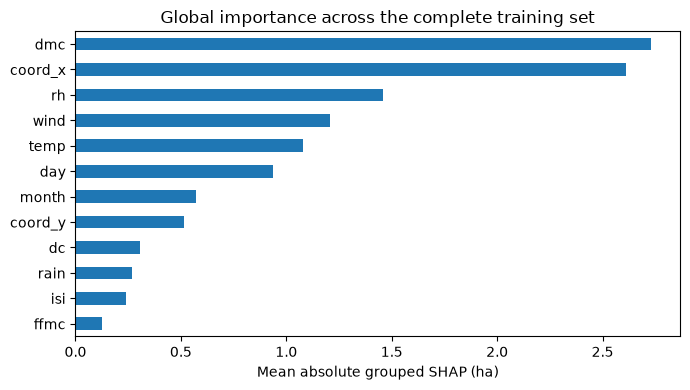

In [27]:
# All training observations are explained, not just the background sample.
training_shap = explainer(train_transformed)
shap.plots.beeswarm(training_shap, max_display=15, show=False)
plt.tight_layout()
plt.show()

# Group one-hot columns back into their original month/day variables.
original_names = numeric_features.copy()
encoder = preprocessor.named_transformers_['categorical']
for name, levels in zip(categorical, encoder.categories_):
    original_names.extend([name] * len(levels))
assert len(original_names) == len(feature_names)
grouped = pd.DataFrame(index=np.arange(len(X_train)))
for name in dict.fromkeys(original_names):
    indices = [i for i, feature in enumerate(original_names) if feature == name]
    grouped[name] = training_shap.values[:, indices].sum(axis=1)
importance = grouped.abs().mean().sort_values(ascending=False)
display(importance.rename('Mean absolute grouped SHAP (ha)').to_frame())
importance.sort_values().plot.barh(figsize=(7, 4))
plt.xlabel('Mean absolute grouped SHAP (ha)')
plt.title('Global importance across the complete training set')
plt.tight_layout()
plt.show()


Largest contributions were:
1. dmc -4.11
2. rh -3.69
3. coord_x +1.93
Positive contributions increase the prediction relative to the reference; negative contributions decrease it. The reference and all contributions add up to the prediction.

Overall importance: Across the complete training set, the highest mean absolute grouped SHAP values can be observed from table and are in order as:
1. dmc 2.731, 
2. coord_x 2.613
3. rh 1.460 and so on.

*(Answer here.)*

I would first investigate removing variables with the lowest SHAP importance. 
Low importance does not automatically mean a variable is useless: predictors may share information, and rare values may matter in particular cases.

To check this, I would compare full and reduced models using the same validation folds. 

Feature ranking, removal and tuning should be done inside the training folds of nested cross-validation, so the outer validation folds give a fair comparison. 

I would keep a variable if removing it increases MAE consistently. 
I would not use the test set to decide which variables to remove. 
Since these test results have already been examined, a revised model would need fresh independent evaluation for a new final performance claim.

## Criteria

The [rubric](./assignment_2_rubric_clean.xlsx) contains the criteria for assessment.

## Submission Information

🚨 **Please review our [Assignment Submission Guide](https://github.com/UofT-DSI/onboarding/blob/main/onboarding_documents/submissions.md)** 🚨 for detailed instructions on how to format, branch, and submit your work. Following these guidelines is crucial for your submissions to be evaluated correctly.

### Submission Parameters:
* Submission Due Date: `HH:MM AM/PM - DD/MM/YYYY`
* The branch name for your repo should be: `assignment-2`
* What to submit for this assignment:
    * This Jupyter Notebook (assignment_2.ipynb) should be populated and should be the only change in your pull request.
* What the pull request link should look like for this assignment: `https://github.com/<your_github_username>/production/pull/<pr_id>`
    * Open a private window in your browser. Copy and paste the link to your pull request into the address bar. Make sure you can see your pull request properly. This helps the technical facilitator and learning support staff review your submission easily.

Checklist:
- [ ] Created a branch with the correct naming convention.
- [ ] Ensured that the repository is public.
- [ ] Reviewed the PR description guidelines and adhered to them.
- [ ] Verify that the link is accessible in a private browser window.

If you encounter any difficulties or have questions, please don't hesitate to reach out to our team via our Slack at the `help` channel. Our Technical Facilitators and Learning Support staff are here to help you navigate any challenges.

# Reference

Cortez,Paulo and Morais,Anbal. (2008). Forest Fires. UCI Machine Learning Repository. https://doi.org/10.24432/C5D88D.